# Installs

In [1]:
%pip install xgboost -v
%pip install matplotlib seaborn
%pip install scikit-learn
%pip install pandas
%pip install numpy
%pip install --upgrade scipy
%pip install optuna

Using pip 25.1 from /Users/jptillman/miniconda3/lib/python3.13/site-packages/pip (python 3.13)
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Imports

In [2]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier, plot_importance
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

/Users/jptillman/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Visualization Helpers

In [3]:
def plot_confusion_matrix(y_true, y_pred, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Fighter 2 Wins', 'Fighter 1 Wins'],
                yticklabels=['Fighter 2 Wins', 'Fighter 1 Wins'])
    plt.title(title)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

def plot_roc_curve(y_true, y_prob, title='ROC Curve'):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2,
             label=f'ROC Curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random Classifier')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

# Experiment 1 — Minimum 1 Fight Experience

Includes fights where **both fighters have at least 1 prior UFC fight**.

## Load Data

In [4]:
TRAIN_PATH_EXP1 = '../data/processed/fights_training_exp1.csv'
VAL_PATH_EXP1   = '../data/processed/fights_validation_exp1.csv'
TEST_PATH_EXP1  = '../data/processed/fights_testing_exp1.csv'

train1 = pd.read_csv(TRAIN_PATH_EXP1)
val1   = pd.read_csv(VAL_PATH_EXP1)
test1  = pd.read_csv(TEST_PATH_EXP1)

columns_to_drop = ['winner']

X_train1 = train1.drop(columns=columns_to_drop)
y_train1  = train1['winner']

X_val1 = val1.drop(columns=columns_to_drop)
y_val1  = val1['winner']

X_test1 = test1.drop(columns=columns_to_drop)
y_test1  = test1['winner']

print(f"Exp1 Training Data: {X_train1.shape[0]} fights, {X_train1.shape[1]} features")
print(f"Exp1 Validation Data: {X_val1.shape[0]} fights")
print(f"Exp1 Testing Data: {X_test1.shape[0]} fights")

Exp1 Training Data: 6644 fights, 65 features
Exp1 Validation Data: 950 fights
Exp1 Testing Data: 1900 fights


## Hyperparameter Optimization
I couldn't get the optimized parameters to beat baseline

In [5]:
def objective_exp1(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'random_state': 42,
        'early_stopping_rounds': 20
    }
    model = XGBClassifier(**param)
    model.fit(X_train1, y_train1, eval_set=[(X_val1, y_val1)], verbose=False)
    preds = model.predict(X_val1)
    return accuracy_score(y_val1, preds)

print("Starting Optuna optimization for Exp1...")
study_exp1 = optuna.create_study(direction='maximize')
study_exp1.enqueue_trial({
    'n_estimators': 500,
    'learning_rate': 0.05,
    'max_depth': 5,
    'subsample': 0.65,
    'colsample_bytree': 0.65
})
study_exp1.optimize(objective_exp1, n_trials=100)

print("\nBest hyperparameters (Exp1):", study_exp1.best_params)
print(f"Best Validation Accuracy (Exp1): {study_exp1.best_value:.2%}")

[I 2026-04-24 11:20:48,249] A new study created in memory with name: no-name-6d747b14-a1f0-4ef6-ac48-bb16d432cbd2


Starting Optuna optimization for Exp1...


[I 2026-04-24 11:20:48,625] Trial 0 finished with value: 0.6136842105263158 and parameters: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.65, 'colsample_bytree': 0.65}. Best is trial 0 with value: 0.6136842105263158.
[I 2026-04-24 11:20:49,023] Trial 1 finished with value: 0.6168421052631579 and parameters: {'n_estimators': 758, 'learning_rate': 0.11448879957640694, 'max_depth': 7, 'subsample': 0.5104155983069582, 'colsample_bytree': 0.8355730672724848}. Best is trial 1 with value: 0.6168421052631579.
[I 2026-04-24 11:20:49,936] Trial 2 finished with value: 0.6178947368421053 and parameters: {'n_estimators': 590, 'learning_rate': 0.09902967389282463, 'max_depth': 9, 'subsample': 0.8107028045157052, 'colsample_bytree': 0.9470047061572092}. Best is trial 2 with value: 0.6178947368421053.
[I 2026-04-24 11:20:50,763] Trial 3 finished with value: 0.6294736842105263 and parameters: {'n_estimators': 763, 'learning_rate': 0.012486292299345883, 'max_depth': 3, 'sub


Best hyperparameters (Exp1): {'n_estimators': 197, 'learning_rate': 0.1614408164381142, 'max_depth': 6, 'subsample': 0.5428508577979201, 'colsample_bytree': 0.5835971727877708}
Best Validation Accuracy (Exp1): 64.95%


## XGB Parameters
Will have to tune these to produce the best results

In [6]:
xgb_model_exp1 = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.649,
    colsample_bytree=0.649,
    random_state=42,
    early_stopping_rounds=20
)

## Training

In [7]:
xgb_model_exp1.fit(
    X_train1, y_train1,
    eval_set=[(X_train1, y_train1), (X_val1, y_val1)],
    verbose=25
)
print("\nExp1 Training Complete!")

[0]	validation_0-logloss:0.68450	validation_1-logloss:0.68590
[25]	validation_0-logloss:0.59325	validation_1-logloss:0.62452
[50]	validation_0-logloss:0.55444	validation_1-logloss:0.61342
[68]	validation_0-logloss:0.53624	validation_1-logloss:0.61333

Exp1 Training Complete!


## Evaluation

EXP1 TEST ACCURACY: 65.84%

Classification Report:
               precision    recall  f1-score   support

           0       0.66      0.66      0.66       950
           1       0.66      0.66      0.66       950

    accuracy                           0.66      1900
   macro avg       0.66      0.66      0.66      1900
weighted avg       0.66      0.66      0.66      1900



<Figure size 1000x800 with 0 Axes>

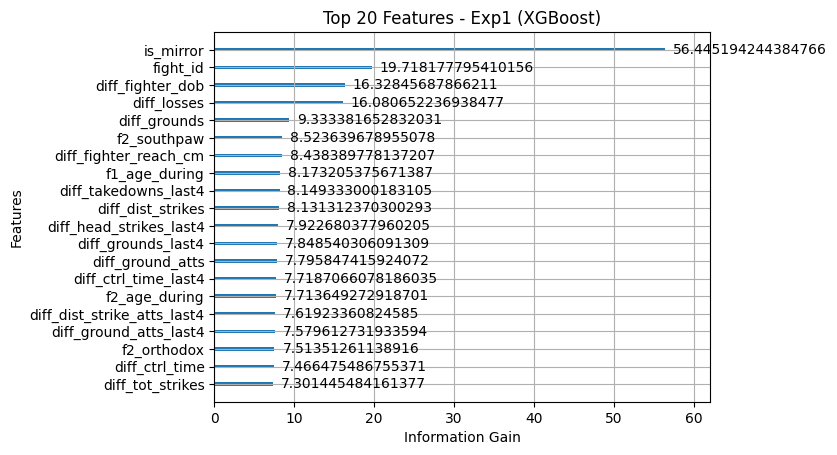

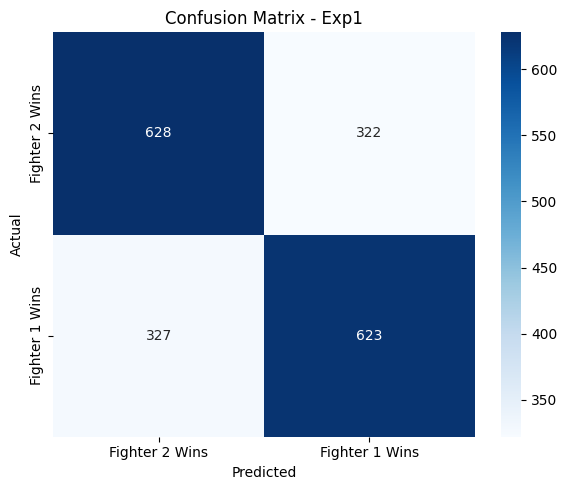

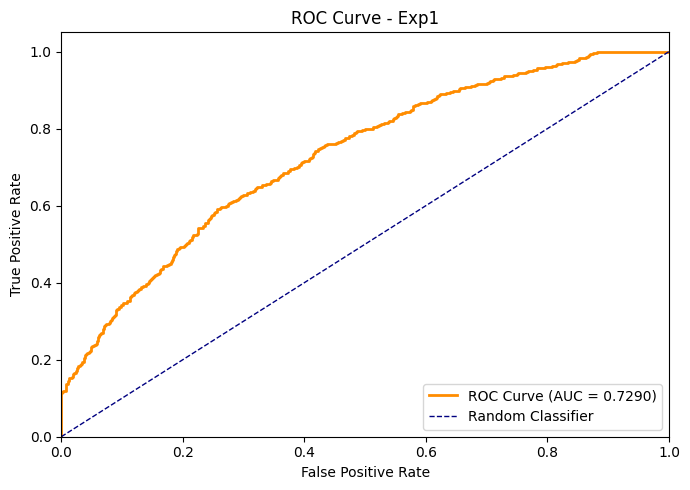

In [8]:
y_pred1      = xgb_model_exp1.predict(X_test1)
y_pred1_prob = xgb_model_exp1.predict_proba(X_test1)[:, 1]

print("=" * 50)
print(f"EXP1 TEST ACCURACY: {accuracy_score(y_test1, y_pred1):.2%}")
print("=" * 50)
print("\nClassification Report:\n", classification_report(y_test1, y_pred1))

# Feature Importance
plt.figure(figsize=(10, 8))
plot_importance(xgb_model_exp1, max_num_features=20, importance_type='gain',
                title='Top 20 Features - Exp1 (XGBoost)', xlabel='Information Gain')
plt.show()

# Confusion Matrix
plot_confusion_matrix(y_test1, y_pred1, title='Confusion Matrix - Exp1')

# ROC Curve
plot_roc_curve(y_test1, y_pred1_prob, title='ROC Curve - Exp1')

# Experiment 2 — Minimum 2 Fights Experience

Includes fights where **both fighters have at least 2 prior UFC fights**.

## Load Data

In [9]:
TRAIN_PATH_EXP2 = '../data/processed/fights_training_exp2.csv'
VAL_PATH_EXP2   = '../data/processed/fights_validation_exp2.csv'
TEST_PATH_EXP2  = '../data/processed/fights_testing_exp2.csv'

train2 = pd.read_csv(TRAIN_PATH_EXP2)
val2   = pd.read_csv(VAL_PATH_EXP2)
test2  = pd.read_csv(TEST_PATH_EXP2)

X_train2 = train2.drop(columns=columns_to_drop)
y_train2  = train2['winner']

X_val2 = val2.drop(columns=columns_to_drop)
y_val2  = val2['winner']

X_test2 = test2.drop(columns=columns_to_drop)
y_test2  = test2['winner']

print(f"Exp2 Training Data: {X_train2.shape[0]} fights, {X_train2.shape[1]} features")
print(f"Exp2 Validation Data: {X_val2.shape[0]} fights")
print(f"Exp2 Testing Data: {X_test2.shape[0]} fights")

Exp2 Training Data: 5212 fights, 65 features
Exp2 Validation Data: 744 fights
Exp2 Testing Data: 1492 fights


## Hyperparameter Optimization
I couldn't get the optimized parameters to beat baseline

In [10]:
def objective_exp2(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'random_state': 42,
        'early_stopping_rounds': 20
    }
    model = XGBClassifier(**param)
    model.fit(X_train2, y_train2, eval_set=[(X_val2, y_val2)], verbose=False)
    preds = model.predict(X_val2)
    return accuracy_score(y_val2, preds)

print("Starting Optuna optimization for Exp2...")
study_exp2 = optuna.create_study(direction='maximize')
study_exp2.enqueue_trial({
    'n_estimators': 500,
    'learning_rate': 0.05,
    'max_depth': 5,
    'subsample': 0.65,
    'colsample_bytree': 0.65
})
study_exp2.optimize(objective_exp2, n_trials=100)

print("\nBest hyperparameters (Exp2):", study_exp2.best_params)
print(f"Best Validation Accuracy (Exp2): {study_exp2.best_value:.2%}")

[I 2026-04-24 11:22:16,563] A new study created in memory with name: no-name-480c8f59-1595-4b39-8770-978eefa2f8cf


Starting Optuna optimization for Exp2...


[I 2026-04-24 11:22:17,596] Trial 0 finished with value: 0.6518817204301075 and parameters: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.65, 'colsample_bytree': 0.65}. Best is trial 0 with value: 0.6518817204301075.
[I 2026-04-24 11:22:17,935] Trial 1 finished with value: 0.6559139784946236 and parameters: {'n_estimators': 360, 'learning_rate': 0.11916547384754841, 'max_depth': 5, 'subsample': 0.7984567010748456, 'colsample_bytree': 0.6405803291380276}. Best is trial 1 with value: 0.6559139784946236.
[I 2026-04-24 11:22:19,204] Trial 2 finished with value: 0.6451612903225806 and parameters: {'n_estimators': 728, 'learning_rate': 0.028593222962177457, 'max_depth': 5, 'subsample': 0.7890720251214914, 'colsample_bytree': 0.880042995589531}. Best is trial 1 with value: 0.6559139784946236.
[I 2026-04-24 11:22:19,977] Trial 3 finished with value: 0.6115591397849462 and parameters: {'n_estimators': 630, 'learning_rate': 0.18404930787004342, 'max_depth': 9, 'subs


Best hyperparameters (Exp2): {'n_estimators': 919, 'learning_rate': 0.02781517364895751, 'max_depth': 3, 'subsample': 0.7085720007635778, 'colsample_bytree': 0.9593643201227381}
Best Validation Accuracy (Exp2): 69.35%


## XGB Parameters
Will have to tune these to produce the best results

In [11]:
xgb_model_exp2 = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.649,
    colsample_bytree=0.649,
    random_state=42,
    early_stopping_rounds=20
)

## Training

In [12]:
xgb_model_exp2.fit(
    X_train2, y_train2,
    eval_set=[(X_train2, y_train2), (X_val2, y_val2)],
    verbose=25
)
print("\nExp2 Training Complete!")

[0]	validation_0-logloss:0.68470	validation_1-logloss:0.68399
[25]	validation_0-logloss:0.58905	validation_1-logloss:0.60842
[50]	validation_0-logloss:0.54576	validation_1-logloss:0.59234
[75]	validation_0-logloss:0.51762	validation_1-logloss:0.58524
[95]	validation_0-logloss:0.49959	validation_1-logloss:0.58599

Exp2 Training Complete!


## Evaluation

EXP2 TEST ACCURACY: 64.01%

Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.65      0.65       746
           1       0.64      0.63      0.63       746

    accuracy                           0.64      1492
   macro avg       0.64      0.64      0.64      1492
weighted avg       0.64      0.64      0.64      1492



<Figure size 1000x800 with 0 Axes>

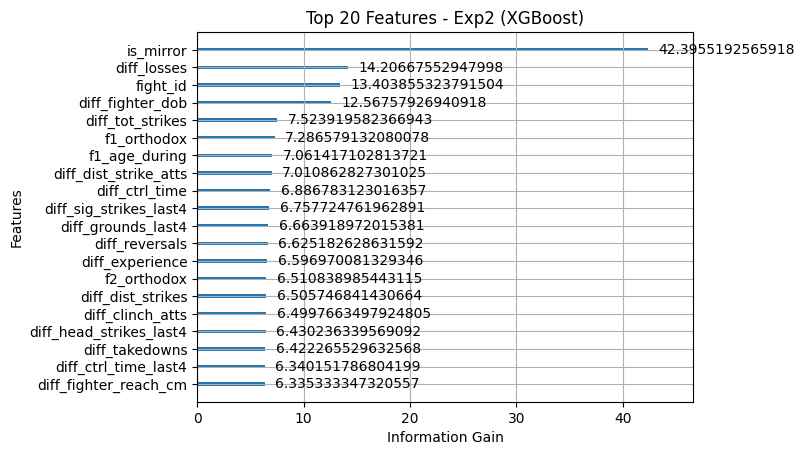

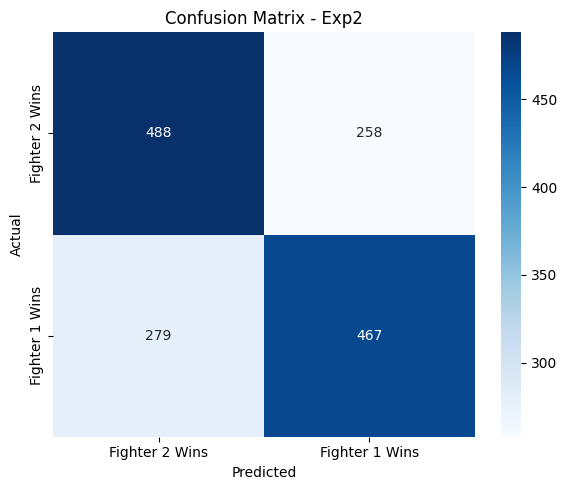

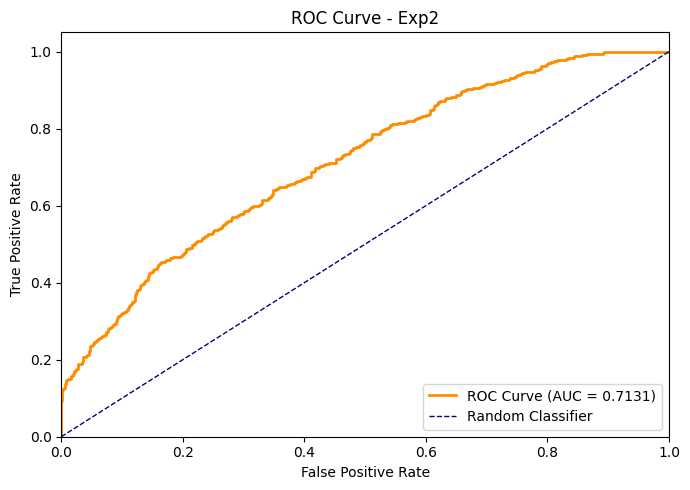

In [13]:
y_pred2      = xgb_model_exp2.predict(X_test2)
y_pred2_prob = xgb_model_exp2.predict_proba(X_test2)[:, 1]

print("=" * 50)
print(f"EXP2 TEST ACCURACY: {accuracy_score(y_test2, y_pred2):.2%}")
print("=" * 50)
print("\nClassification Report:\n", classification_report(y_test2, y_pred2))

# Feature Importance
plt.figure(figsize=(10, 8))
plot_importance(xgb_model_exp2, max_num_features=20, importance_type='gain',
                title='Top 20 Features - Exp2 (XGBoost)', xlabel='Information Gain')
plt.show()

# Confusion Matrix
plot_confusion_matrix(y_test2, y_pred2, title='Confusion Matrix - Exp2')

# ROC Curve
plot_roc_curve(y_test2, y_pred2_prob, title='ROC Curve - Exp2')